# Step 0: Loading data and checking basic information

## 0-1: Import libraries

In [34]:
import gc
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from pathlib import Path

from sklearn.model_selection import GroupKFold

pd.set_option("display.max_columns", 50)
pd.set_option("display.max_colwidth", 100)

sns.set_theme(style="whitegrid")

## 0-2: Check data

In [2]:
DATA_DIR = Path("/kaggle/input/competitions/enveda-CASMI26-molecule-id-mass-spectra")

for path in DATA_DIR.iterdir():
    print(path)

/kaggle/input/competitions/enveda-CASMI26-molecule-id-mass-spectra/sample_submission.csv
/kaggle/input/competitions/enveda-CASMI26-molecule-id-mass-spectra/train.parquet
/kaggle/input/competitions/enveda-CASMI26-molecule-id-mass-spectra/test.parquet


In [3]:
train = pd.read_parquet(DATA_DIR / "train.parquet")
test = pd.read_parquet(DATA_DIR / "test.parquet")

print("train:", train.shape)
print("test:", test.shape)

train: (2539608, 18)
test: (1213, 12)


In [4]:
print("=== TRAIN ===")
display(
    pd.DataFrame({
        "column": train.columns,
        "dtype": train.dtypes.astype(str).values
    })
)

print("\n=== TEST ===")
display(
    pd.DataFrame({
        "column": test.columns,
        "dtype": test.dtypes.astype(str).values
    })
)

train.head(3)

=== TRAIN ===


,column,dtype
0,ingest_lib,object
1,normalized_smiles,object
2,inchikey,object
3,inchikey14,object
4,molecular_formula,object
5,ionization_mode,object
6,instrument_type,object
7,adduct,object
8,adduct_orig,object
9,precursor_mz,float64



=== TEST ===


,column,dtype
0,molecule_id,object
1,spectrum_id,object
2,ms2_mzs,object
3,ms2_normalized_intensities,object
4,base_peak_intensity,float64
5,adduct,object
6,ionization_mode,object
7,instrument_type,object
8,precursor_mz,float64
9,collision_energy_orig,object


,ingest_lib,normalized_smiles,inchikey,inchikey14,molecular_formula,ionization_mode,instrument_type,adduct,adduct_orig,precursor_mz,precursor_error_ppm,ms2_mzs,ms2_normalized_intensities,num_peaks,base_peak_intensity,collision_energy_ev,collision_energy_orig,collision_energy_orig_units
0,drug_plus,O=C1NC(=O)c2cc(Nc3ccccc3)c(Nc3ccccc3)cc21,AAALVYBICLMAMA-UHFFFAOYSA-N,AAALVYBICLMAMA,C20H15N3O2,positive,None,[M+H]+,[M+H]+,330.1237,1.671398,"[92.0495, 93.0573, 94.0607, 116.107, 123.1168, 124.1203, 133.0761, 142.0777, 142.1226, 166.0655,...","[0.0171037726229424, 0.328091214993177, 0.0107218611515595, 0.0260808387356118, 0.00689810236918...",52,NaN,None,None,unknown
1,drug_plus,C#Cc1cccc(Nc2ncnc3cc(OCCOC)c(OCCOC)cc23)c1,AAKJLRGGTJKAMG-UHFFFAOYSA-N,AAKJLRGGTJKAMG,C22H23N3O4,positive,None,[M+K]+,[M+K]+,432.1320,1.302193,"[82.1451, 89.0599, 158.9638, 248.0836, 250.0985, 251.1026, 276.0778, 277.0857, 278.0937, 280.099...","[0.00144055962319783, 0.959302375462881, 0.5, 0.000515701917270155, 0.0376652132213415, 0.002495...",28,NaN,None,None,unknown
2,drug_plus,CC1(C)CCC(C)(C)c2cc(C(O)C(O)=Nc3ccc(C(=O)O)cc3F)ccc21,AANFHDFOMFRLLR-UHFFFAOYSA-N,AANFHDFOMFRLLR,C23H26FNO4,positive,None,[M+Na]+,[M+Na]+,422.1738,1.316437,"[91.0539, 111.117, 131.0856, 150.035, 171.0803, 187.148, 188.1531, 194.0247, 194.034, 194.034, 2...","[0.00262159533923045, 0.0184752871374318, 0.00470403847262502, 0.00290264206747667, 0.0041562943...",41,NaN,None,None,unknown


In [5]:
train_cols = set(train.columns)
test_cols = set(test.columns)

print("Common columns:")
print(sorted(train_cols & test_cols))

print("\nTrain only:")
print(sorted(train_cols - test_cols))

print("\nTest only:")
print(sorted(test_cols - train_cols))

Common columns:
['adduct', 'base_peak_intensity', 'collision_energy_ev', 'collision_energy_orig', 'collision_energy_orig_units', 'instrument_type', 'ionization_mode', 'ms2_mzs', 'ms2_normalized_intensities', 'precursor_mz']

Train only:
['adduct_orig', 'inchikey', 'inchikey14', 'ingest_lib', 'molecular_formula', 'normalized_smiles', 'num_peaks', 'precursor_error_ppm']

Test only:
['molecule_id', 'spectrum_id']


# Step 1: Assessing data quality, missing values, and duplicates.
The goal at this stage is not to clean the data, but rather to determine which data can be trusted and which data requires closer attention.

## 1-1: assess missing values

In [6]:
def missing_report(df):
    report = pd.DataFrame({
        "dtype": df.dtypes.astype(str),
        "missing_count": df.isna().sum(),
        "missing_rate": df.isna().mean() * 100,
    })
    return report.sort_values("missing_rate", ascending=False)

print("train:")
display(missing_report(train))
print("test:")
display(missing_report(test))

train:


,dtype,missing_count,missing_rate
base_peak_intensity,float64,1163138,45.799903
collision_energy_ev,object,337443,13.287208
collision_energy_orig,object,320464,12.618640
instrument_type,object,33053,1.301500
precursor_error_ppm,float64,4286,0.168766
ingest_lib,object,0,0.000000
normalized_smiles,object,0,0.000000
inchikey,object,0,0.000000
molecular_formula,object,0,0.000000
inchikey14,object,0,0.000000


test:


,dtype,missing_count,missing_rate
molecule_id,object,0,0.0
spectrum_id,object,0,0.0
ms2_mzs,object,0,0.0
ms2_normalized_intensities,object,0,0.0
base_peak_intensity,float64,0,0.0
adduct,object,0,0.0
ionization_mode,object,0,0.0
instrument_type,object,0,0.0
precursor_mz,float64,0,0.0
collision_energy_orig,object,0,0.0


## 1-2: check duplicates
Since the same molecule is measured multiple times - using different collision energies or adducts - the occurrence of duplicate `inchikey14` values is not anomalous.

In [7]:
print("Train unique inchikey14:",
     train["inchikey14"].nunique())
print("Train unique normalized_smiles:",
     train["normalized_smiles"].nunique())
print("Train duplicated inchikey14:",
     train["inchikey14"].duplicated().sum())

Train unique inchikey14: 275810
Train unique normalized_smiles: 277566
Train duplicated inchikey14: 2263798


## 1-3: verification of spectral sequence consistency
The training data includes errors representing the difference between the measured precursor mass and the mass calculated from the chemical structure `precursor_error_ppm`.  
Spectra with large errors may have issues related to their labels or the quality of the measurements.  
However, since excluding outliers could result in the loss of certain libraries or chemical structures, the first step is to examine the distribution of these errors and assess any differences across `ingest_lib`.

In [8]:
def check_spectrum_arrays(df):
    mzs = df["ms2_mzs"]
    intensities = df["ms2_normalized_intensities"]

    mz_len = mzs.map(
        lambda x: len(x) if isinstance(x, (list, np.ndarray)) else -1
    )

    int_len = intensities.map(
        lambda x: len(x) if isinstance(x, (list, np.ndarray)) else -1
    )

    result = pd.DataFrame({
        "mz_length": mz_len,
        "intensity_length": int_len
    })

    result["same_length"] = (
        result["mz_length"] == result["intensity_length"]
    )

    return result

array_check = check_spectrum_arrays(train)
display(array_check["same_length"].value_counts())

same_length
True    2539608
Name: count, dtype: int64

In [9]:
def check_finite(values):
    if not isinstance(values, (list, np.ndarray)):
        return False

    return np.isfinite(
        np.asarray(values, dtype=float)
    ).all()

sample = train.sample(
    min(10000, len(train)),
    random_state=1
)

print(
    "Invalid m/z arrays:",
    (~sample["ms2_mzs"].map(check_finite)).sum()
)

print(
    "Invalid intensity arrays:",
    (~sample["ms2_normalized_intensities"].map(check_finite)).sum()
)

Invalid m/z arrays: 0
Invalid intensity arrays: 0


,precursor_error_ppm
count,2.535322e+06
mean,1.845726e+03
std,5.117525e+05
min,-2.106149e+01
1%,3.002888e-02
5%,1.544535e-01
25%,7.755261e-01
50%,1.512113e+00
75%,2.345292e+00
95%,1.718147e+01


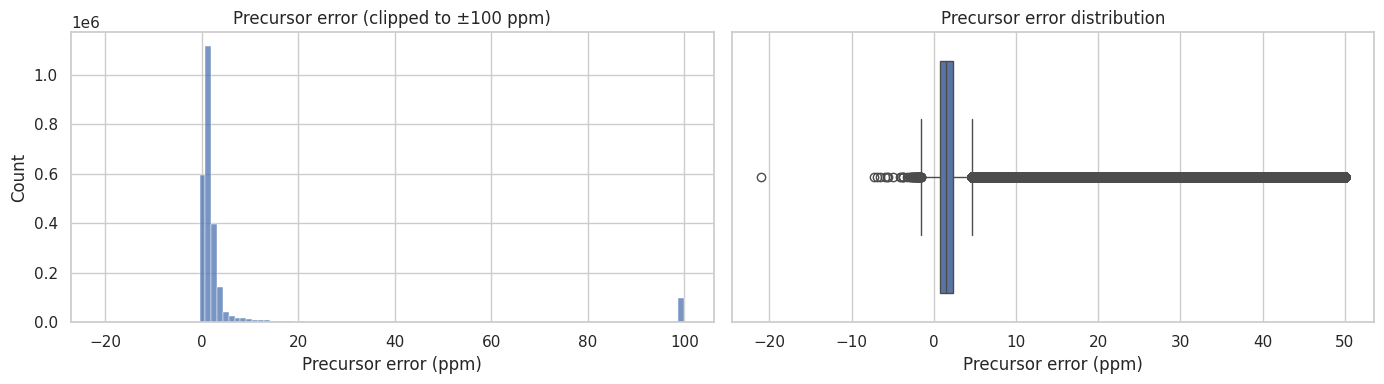

In [10]:
display(
    train["precursor_error_ppm"]
    .describe(percentiles=[0.01, 0.05, 0.25, 0.5, 0.75, 0.95, 0.99])
    .to_frame()
)

fig, axes = plt.subplots(1, 2, figsize=(14, 4))

sns.histplot(
    train["precursor_error_ppm"].dropna().clip(-100, 100),
    bins=100,
    ax=axes[0]
)
axes[0].set_title("Precursor error (clipped to ±100 ppm)")
axes[0].set_xlabel("Precursor error (ppm)")

sns.boxplot(
    x=train["precursor_error_ppm"].dropna().clip(-50, 50),
    ax=axes[1]
)
axes[1].set_title("Precursor error distribution")
axes[1].set_xlabel("Precursor error (ppm)")

plt.tight_layout()
plt.show()

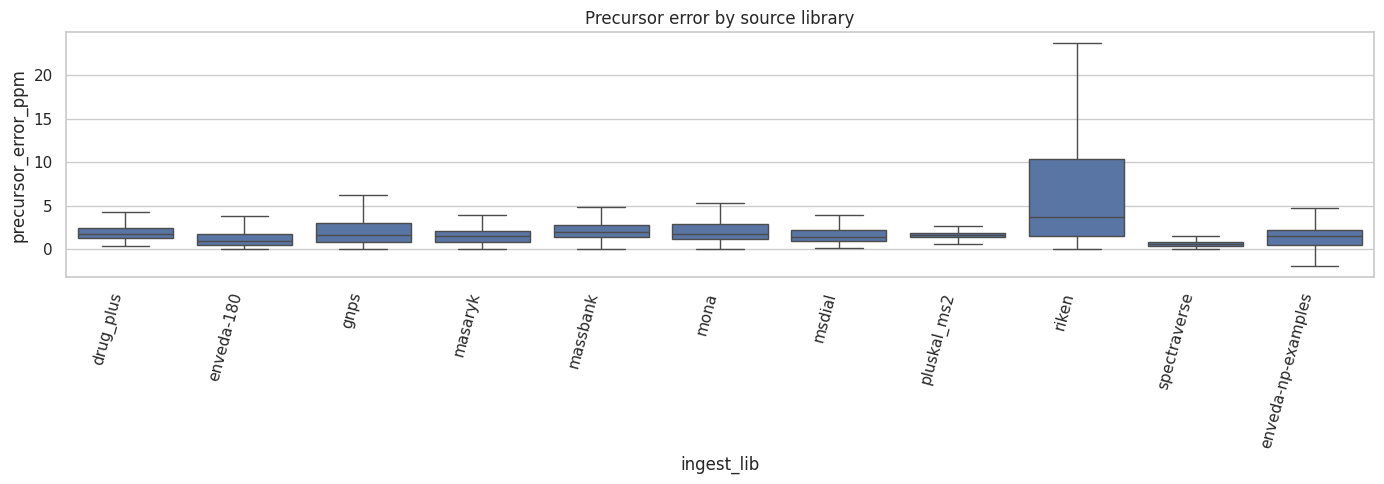

In [11]:
plt.figure(figsize=(14, 5))

sns.boxplot(
    data=train,
    x="ingest_lib",
    y="precursor_error_ppm",
    showfliers=False
)

plt.xticks(rotation=75, ha="right")
plt.title("Precursor error by source library")
plt.tight_layout()
plt.show()

# Step 2: Analyzing the distribution molecules and spectra
This is one of the most critical EDA tasks for this competition, as the training data is structured by spectra, while submissions and evaluations are based on individual molecules.

## 2-1: The number of spectra per one molecule.

count    275810.000000
mean          9.207817
std          21.069560
min           1.000000
50%           6.000000
75%           9.000000
90%          14.000000
95%          21.000000
99%          79.000000
max        1468.000000
Name: n_spectra, dtype: float64

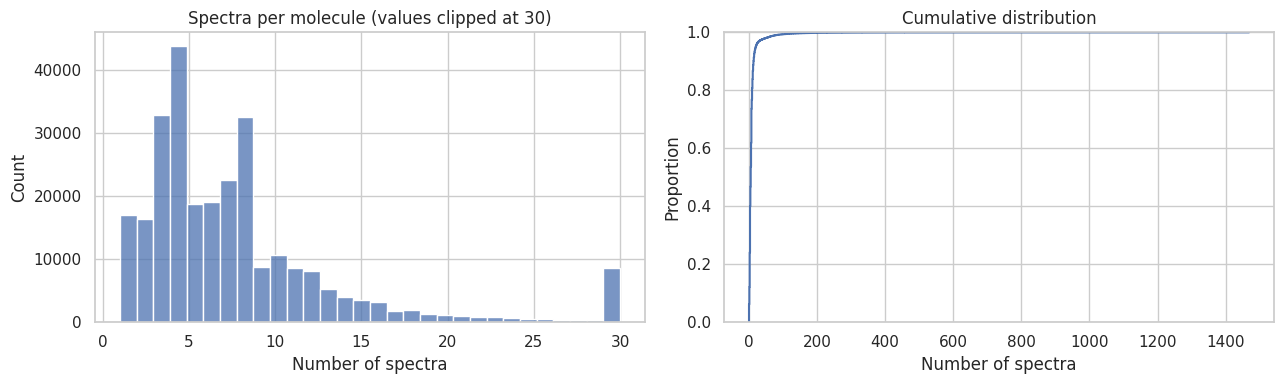

In [12]:
spectra_per_molecule = train.groupby("inchikey14").size().rename("n_spectra")

display(spectra_per_molecule.describe(
    percentiles=[0.5, 0.75, 0.9, 0.95, 0.99]
))

fig, axes = plt.subplots(1, 2, figsize=(13, 4))

sns.histplot(
    spectra_per_molecule.clip(upper=30),
    bins=30,
    ax=axes[0]
)
axes[0].set_title("Spectra per molecule (values clipped at 30)")
axes[0].set_xlabel("Number of spectra")

sns.ecdfplot(spectra_per_molecule, ax=axes[1])
axes[1].set_title("Cumulative distribution")
axes[1].set_xlabel("Number of spectra")

plt.tight_layout()
plt.show()

In [13]:
test_spectra_per_molecule = test.groupby("molecule_id").size()

display(
    pd.concat(
        [
            spectra_per_molecule.describe().rename("train"),
            test_spectra_per_molecule.describe().rename("test"),
        ],
        axis=1
    )
)

,train,test
count,275810.000000,400.000000
mean,9.207817,3.032500
std,21.069560,1.382469
min,1.000000,1.000000
25%,4.000000,2.000000
50%,6.000000,3.000000
75%,9.000000,4.000000
max,1468.000000,9.000000


## 2-2: Measurement conditions per molecule
Since measurement conditions can vary even for the same molecule, the number of adducts and the number of measurement instruments used were tabulated for each molecule.

,n_spectra,n_adducts,n_ionization_modes,n_instruments,n_libraries,molecular_formula
inchikey14,,,,,,
AAAAMGLVZZXVDT,5,2,2,1,1,C18H25N5O
AAABMNXUOFPYQK,5,1,1,1,1,C25H43NO10
AAAIIIBNBXOKHO,2,1,1,1,1,C16H18NO7P
AAAILXDLOQPKFL,9,3,1,1,1,C15H20N2O2S
AAAJHMPMZMRLLC,13,4,2,1,1,C18H16F2N2O3


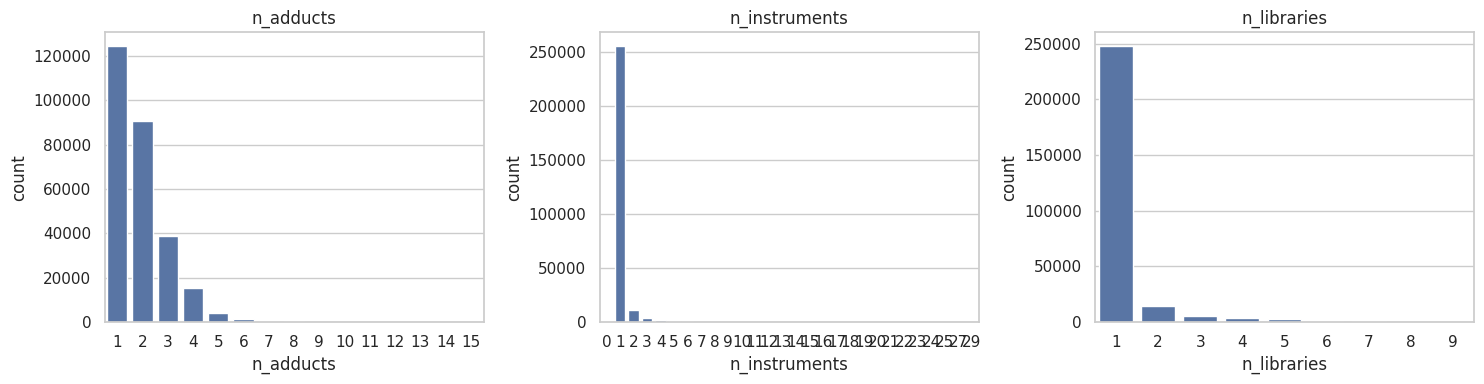

In [14]:
molecule_summary = (
    train.groupby("inchikey14")
    .agg(
        n_spectra=("inchikey14", "size"),
        n_adducts=("adduct", "nunique"),
        n_ionization_modes=("ionization_mode", "nunique"),
        n_instruments=("instrument_type", "nunique"),
        n_libraries=("ingest_lib", "nunique"),
        molecular_formula=("molecular_formula", "first")
    )
)

display(molecule_summary.head())

fig, axes = plt.subplots(1, 3, figsize=(15, 4))

for col, ax in zip(
    ["n_adducts", "n_instruments", "n_libraries"],
    axes
):
    sns.countplot(
        data=molecule_summary,
        x=col,
        ax=ax
    )
    ax.set_title(col)

plt.tight_layout()
plt.show()

## 2-3: Frequency of molecular structures
This distribution is also relevant to how training data is weighted when developing a model.  
For instance, if the model becomes biased toward frequently occuring molecules, its generalization performance on unseen structures may decline.

In [15]:
structure_frequency = (
    train["inchikey14"]
    .value_counts()
)

print("Unique structures:", len(structure_frequency))
print("Single spectrum:", (structure_frequency == 1).sum())
print("5+ spectra:", (structure_frequency >= 5).sum())
print("20+ spectra:", (structure_frequency >= 20).sum())

Unique structures: 275810
Single spectrum: 17033
5+ spectra: 165492
20+ spectra: 15427


## 2-4: Differences in measurement conditions for the same molecule

In [16]:
molecule_adduct = (
    train.groupby("inchikey14")["adduct"]
    .nunique()
)

energy_signature = train["collision_energy_ev"].map(
    lambda x: tuple(x)
    if isinstance(x, (list, np.ndarray))
    else None
)

molecule_energy = (
    pd.DataFrame({
        "inchikey14": train["inchikey14"],
        "energy": energy_signature
    })
    .groupby("inchikey14")["energy"]
    .nunique()
)

print("Molecules with multiple adducts:",
     (molecule_adduct > 1).sum())
print("Molecules with multiple energy settings:",
     (molecule_energy > 1).sum())

Molecules with multiple adducts: 151289
Molecules with multiple energy settings: 233657


Since `molecule_ids` were missing in the training data, grouping was performed using InChIKeys.  
However, it is important to note that the grouping method used during the actual evaluation process differs from the normalization approach employed by RDKit.  
Specifically, approximately 1 in every 22 pairs of structures in the training set are treated as identical, even though they are actually distinct.  

Based on the above distribution, the following hypotheses can be formulated:
- For molecules with multiple spectra, integrating information from each spectrum may improve the ranking of candidates.
- If the distribution of the number of spectra differs significantly between the training data and the test data, the validation methodology must be adjusted accordingly.
- Training the model primarily on molecules with a large number of spectra could lead to an inaccurate assessment of actual performance at the molecular 

# Step 3: Analyzing MS/MS spectra

## 3-1: Distribution of the number of peaks

count    2.539608e+06
mean     1.582158e+02
std      5.168801e+02
min      1.000000e+00
10%      5.000000e+00
25%      1.400000e+01
50%      4.200000e+01
75%      1.640000e+02
90%      4.160000e+02
99%      1.346930e+03
max      7.331800e+04
Name: num_peaks, dtype: float64

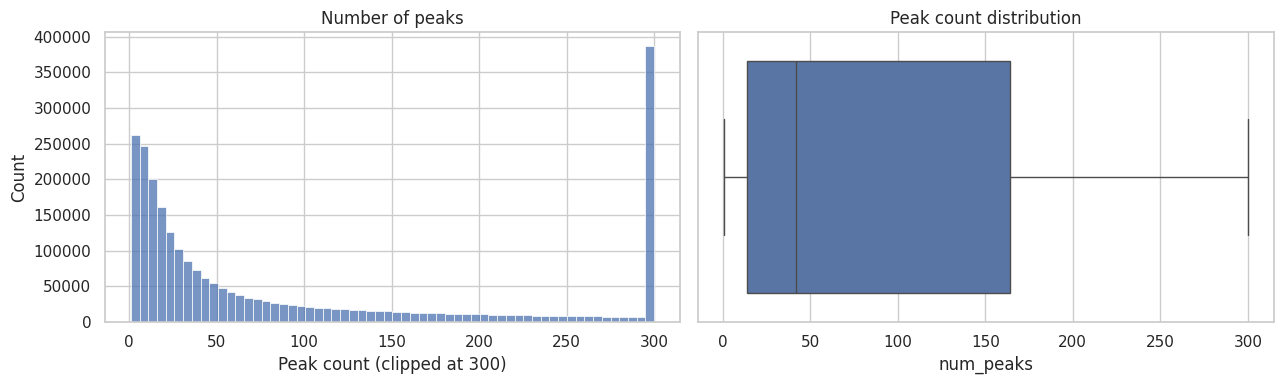

In [17]:
display(
    train["num_peaks"].describe(
        percentiles=[0.1, 0.25, 0.5, 0.75, 0.9, 0.99]
    )
)

fig, axes = plt.subplots(1, 2, figsize=(13, 4))

sns.histplot(
    train["num_peaks"].clip(upper=300),
    bins=60,
    ax=axes[0]
)
axes[0].set_title("Number of peaks")
axes[0].set_xlabel("Peak count (clipped at 300)")

sns.boxplot(
    x=train["num_peaks"].clip(upper=300),
    ax=axes[1]
)
axes[1].set_title("Peak count distribution")

plt.tight_layout()
plt.show()

## 3-2: Distribution of m/z
Expanding the peaks for the entire set of spectra consumes a large amount of memory, so we will limit the scope to 10,000 spectra for now.

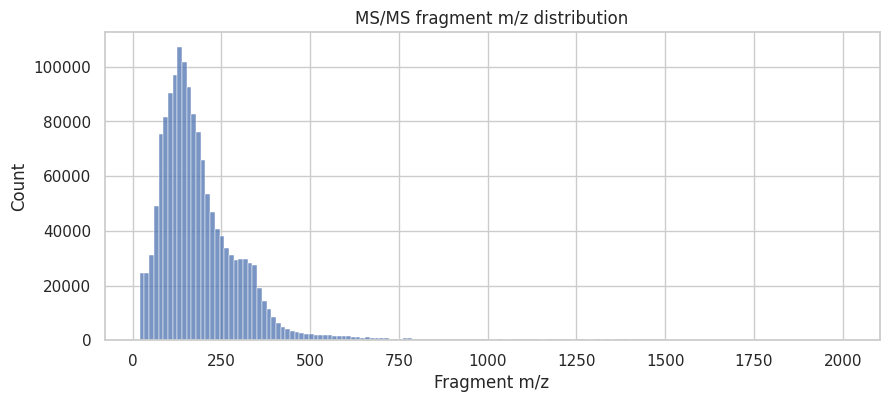

In [18]:
spectrum_sample = train.sample(
    n=min(10000, len(train)),
    random_state=1
)

all_mzs = np.concatenate(
    spectrum_sample["ms2_mzs"].map(
        lambda x: np.asarray(x, dtype=np.float32)
    ).values
)

plt.figure(figsize=(10, 4))

sns.histplot(
    all_mzs,
    bins=150
)

plt.xlabel("Fragment m/z")
plt.title("MS/MS fragment m/z distribution")

plt.show()

## 3-3: Distribution of intensities
The intensities are normalized such that the maximum peak within each spectrum equals 1.  
Therefore, the focus is on the relative intensities between peaks within a spectrum, rather than on the absolute intensity values.

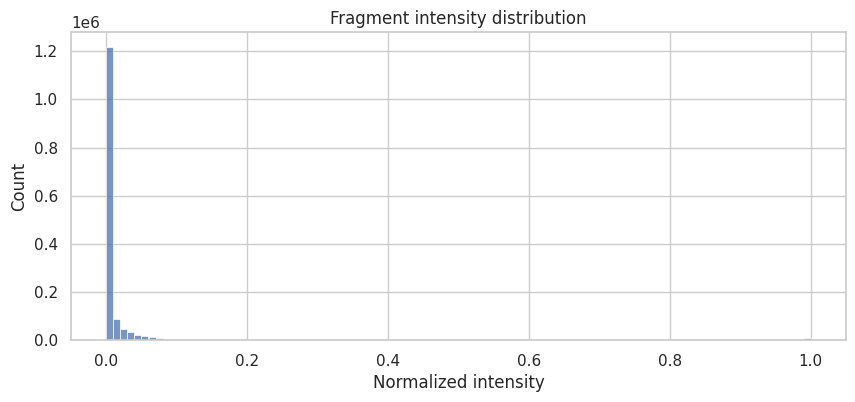

In [19]:
all_intensities = np.concatenate(
    spectrum_sample["ms2_normalized_intensities"].map(
        lambda x: np.asarray(x, dtype=np.float32)
    ).values
)

plt.figure(figsize=(10, 4))

sns.histplot(
    all_intensities,
    bins=100
)

plt.xlabel("Normalized intensity")
plt.title("Fragment intensity distribution")

plt.show()

## 3-4: Visualize representative spectra

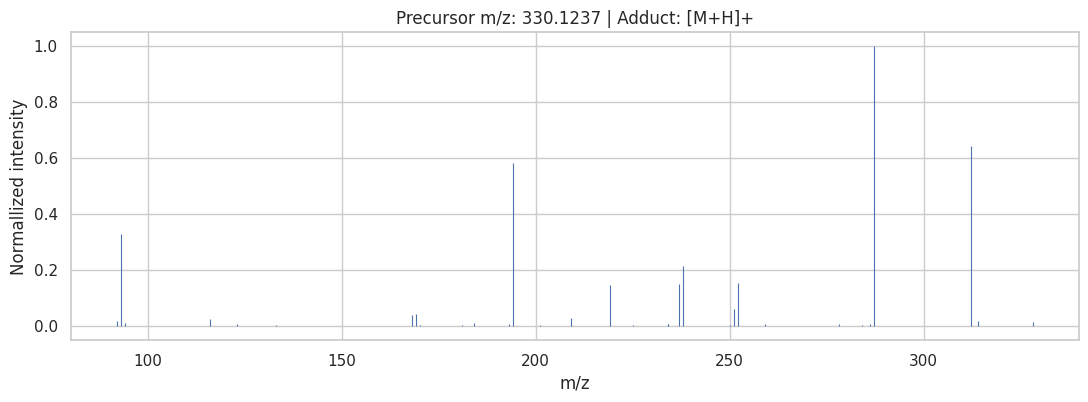

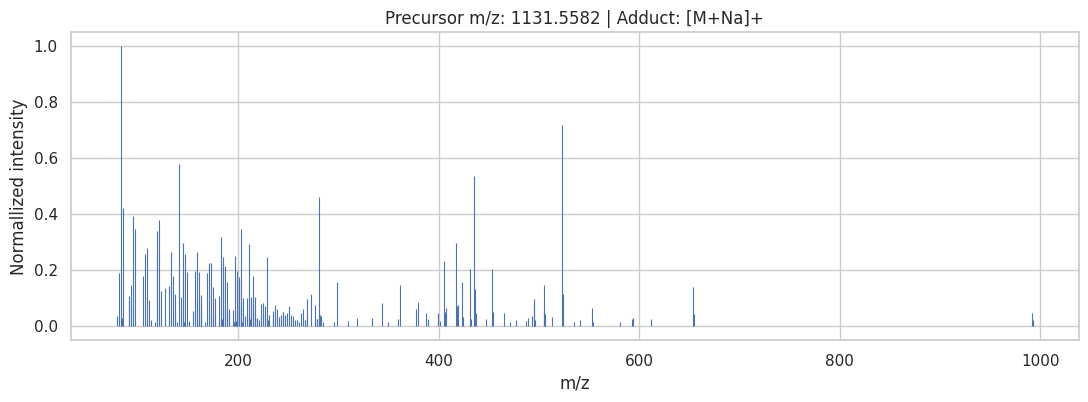

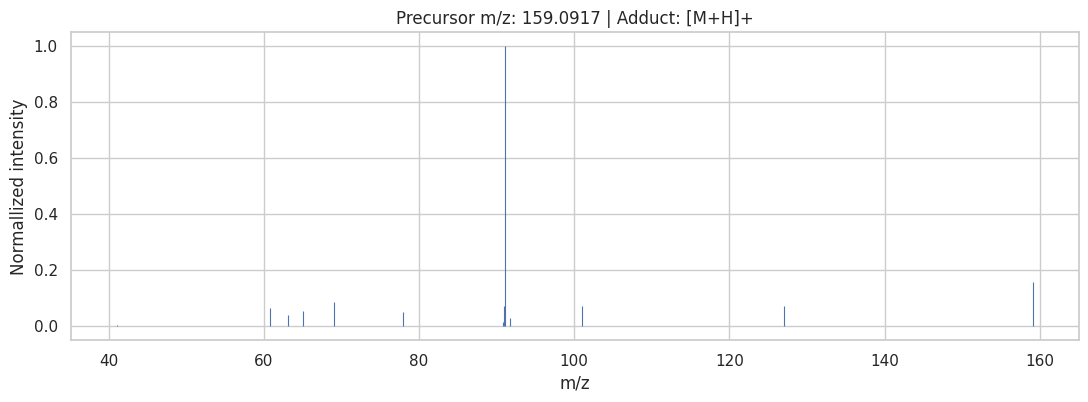

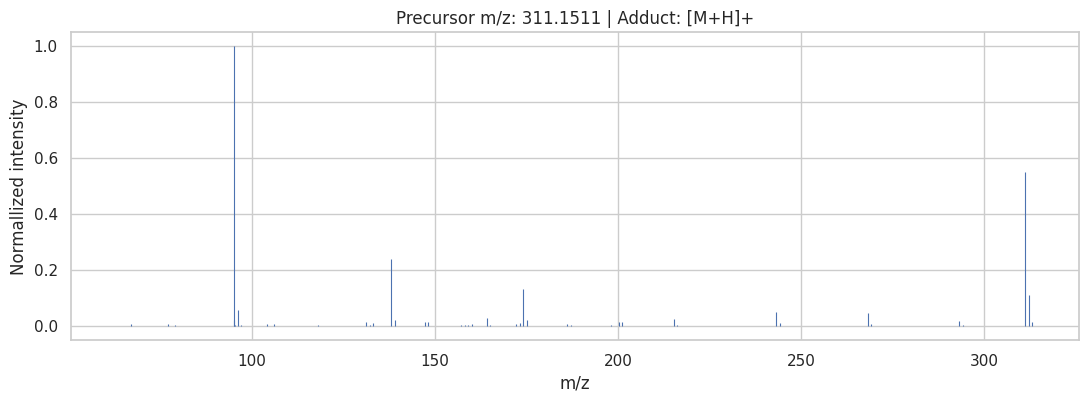

In [20]:
def plot_spectrum(df, idx):
    row = df.iloc[idx]

    mzs = np.asarray(row["ms2_mzs"], dtype=float)
    intensities = np.asarray(
        row["ms2_normalized_intensities"],
        dtype=float
    )

    order = np.argsort(mzs)

    plt.figure(figsize=(13, 4))

    plt.vlines(
        mzs[order],
        0,
        intensities[order],
        linewidth=0.8
    )

    plt.xlabel("m/z")
    plt.ylabel("Normallized intensity")

    plt.title(
        f"Precursor m/z: {row['precursor_mz']:.4f} | "
        f"Adduct: {row['adduct']}"
    )

    plt.show()

for idx in [0, 100, 1000, 10000]:
    if idx < len(train):
        plot_spectrum(train, idx)

## 3-5: Distribution of collision energy
Since a single collision energy may not be sufficient to fully dissociate precursor ions, multiple collision energies are sometimes used.

,collision_energy_ev
count,3.273593e+06
mean,3.594668e+01
std,1.958957e+01
min,0.000000e+00
25%,2.000000e+01
50%,4.000000e+01
75%,4.920000e+01
max,4.660000e+02


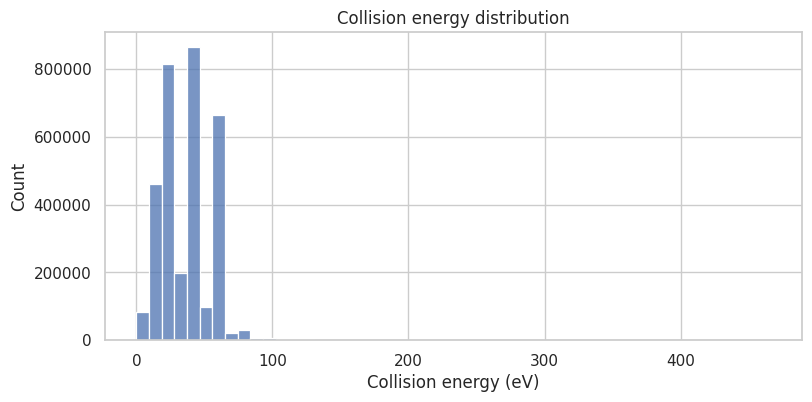

collision_energy_ev
0     337443
1    1706663
2      12562
3     394599
4      83712
5       4613
6         16
Name: count, dtype: int64

In [21]:
energy_values = []

for values in train["collision_energy_ev"]:
    if isinstance(values, (list, np.ndarray)):
        energy_values.extend(values)

energy_df = pd.DataFrame({
    "collision_energy_ev": energy_values
})

display(energy_df.describe())
plt.figure(figsize=(9, 4))

sns.histplot(
    energy_df["collision_energy_ev"],
    bins=50
)

plt.title("Collision energy distribution")
plt.xlabel("Collision energy (eV)")

plt.show()

energy_count = train["collision_energy_ev"].map(
    lambda x: len(x)
    if isinstance(x, (list, np.ndarray))
    else 0
)

display(energy_count.value_counts().sort_index())

# Step 4: Analysis of chemical characteristics
Because isomers - compounds with the same molecular formula but different structures - can exist, amolecular formula alone is insufficient to uniquely identify a structure.  
However, it is highly valuable when used in combination with precursor mass to narrow down the list of candidates.

## 4-1: Frequency of molecular formula

In [22]:
formula_counts = (
    train.groupby("inchikey14")["molecular_formula"]
    .first()
    .value_counts()
)

display(formula_counts.head(30).to_frame("count"))

,count
molecular_formula,
C19H24N4O2,477
C18H24N4O2,463
C19H26N4O2,422
C17H22N4O2,409
C18H22N4O2,380
C18H23N3O2,354
C19H23N3O3,350
C18H23N3O3,350
C20H25N3O2,348


## 4-2: Distribution of adducts

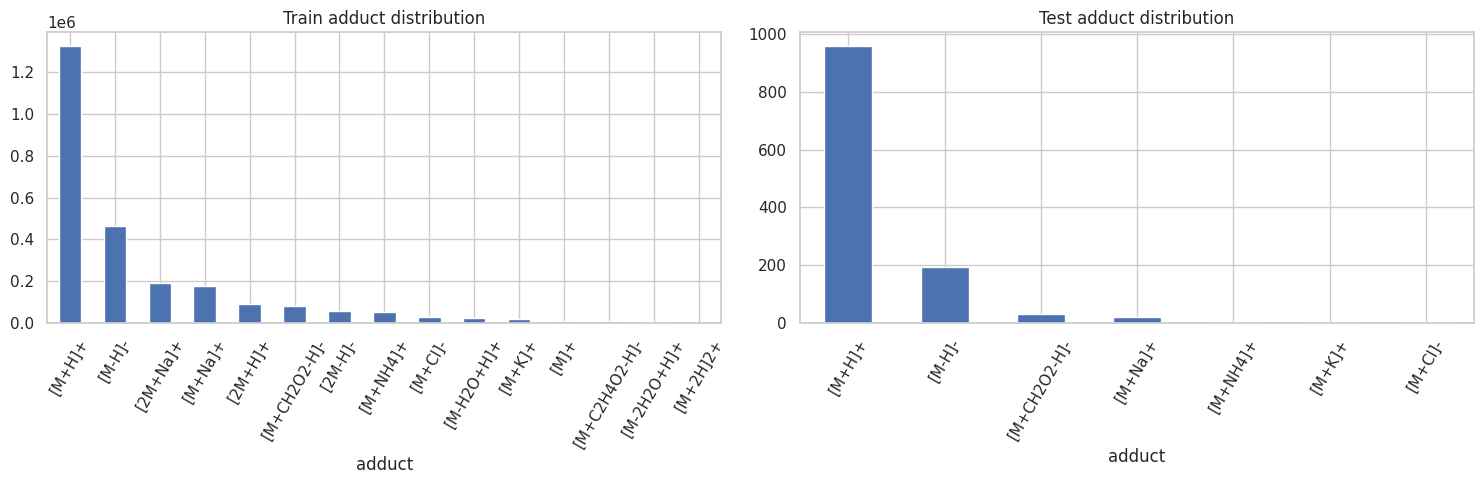

In [23]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

train["adduct"].value_counts().head(15).plot(
    kind="bar",
    ax=axes[0]
)

axes[0].set_title("Train adduct distribution")
axes[0].tick_params(axis="x", rotation=60)

test["adduct"].value_counts().plot(
    kind="bar",
    ax=axes[1]
)

axes[1].set_title("Test adduct distribution")
axes[1].tick_params(axis="x", rotation=60)

plt.tight_layout()
plt.show()

## 4-3: Distribution of molecules

In [24]:
!pip install rdkit

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 31.8/31.8 MB 51.7 MB/s  0:00:00m0:00:0100:01


In [25]:
from rdkit import Chem
from rdkit.Chem import Descriptors

def calc_mol_weight(smiles):
    mol = Chem.MolFromSmiles(smiles)

    if mol is None:
        return np.nan

    return Descriptors.MolWt(mol)

count    275810.000000
mean        358.500557
std         133.088929
min          31.058000
25%         304.419000
50%         333.457000
75%         366.421000
max        3401.902000
Name: mol_weight, dtype: float64

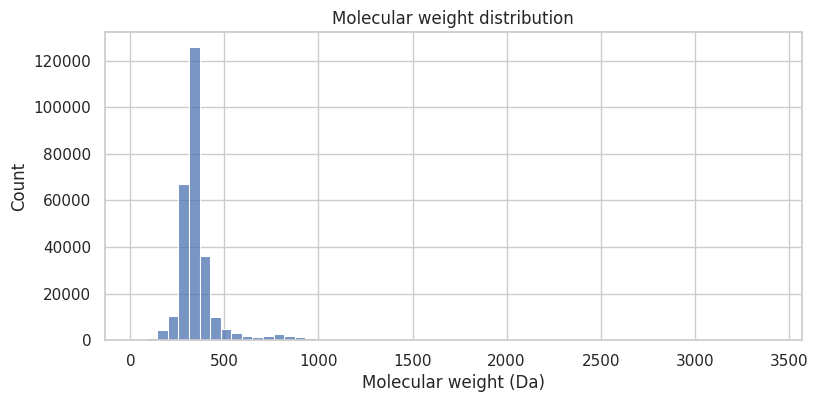

In [26]:
unique_molecules = (
    train[["inchikey14", "normalized_smiles", "molecular_formula"]]
    .drop_duplicates("inchikey14")
    .copy()
)

unique_molecules["mol_weight"] = (
    unique_molecules["normalized_smiles"]
    .map(calc_mol_weight)
)

display(unique_molecules["mol_weight"].describe())

plt.figure(figsize=(9, 4))

sns.histplot(
    unique_molecules["mol_weight"].dropna(),
    bins=60
)

plt.xlabel("Molecular weight (Da)")
plt.title("Molecular weight distribution")

plt.show()

# Step 5: Analysis of Measurement Conditions and Data Sources

## 5-1: Characteristics by library
Identify which libraries provide large volumes of data and which offer relatively better measurement quality.

In [27]:
library_summary = (
    train.groupby("ingest_lib")
    .agg(
        n_spectra=("inchikey14", "size"),
        n_structures=("inchikey14", "nunique"),
        median_precursor_mz=("precursor_mz", "median"),
        median_peak_count=("num_peaks", "median"),
        median_error_ppm=("precursor_error_ppm", "median"),
    )
    .sort_values("n_spectra", ascending=False)
)

display(library_summary)

,n_spectra,n_structures,median_precursor_mz,median_peak_count,median_error_ppm
ingest_lib,,,,,
enveda-180,1153785,182941,347.23410,138.0,0.981064
pluskal_ms2,527581,46821,343.11110,21.0,1.663812
riken,347171,15892,399.14000,9.0,3.752602
gnps,220849,45750,363.14600,46.0,1.673418
massbank,101727,9180,297.12340,11.0,1.948510
mona,92416,11681,334.23770,57.0,1.799443
spectraverse,50933,9631,748.52870,47.0,0.650375
msdial,40765,9127,374.15980,11.0,1.470226
drug_plus,2545,2539,322.17610,108.0,1.733591


## 5-2: Characteristics by instrument
Since measurements in the test set are performed using a Bruker timsTOF, it is important to verify that the training data includes data acquired using the same instrument.

In [28]:
instrument_summary = (
    train.groupby("instrument_type", dropna=False)
    .agg(
        n_spectra=("inchikey14", "size"),
        n_structures=("inchikey14", "nunique"),
        median_peak_count=("num_peaks", "median"),
        median_error_ppm=("precursor_error_ppm", "median"),
    )
    .sort_values("n_spectra", ascending=False)
)

display(instrument_summary.head(30))

,n_spectra,n_structures,median_peak_count,median_error_ppm
instrument_type,,,,
timsTOF,1154969,183191,138.0,0.981415
Orbitrap,745562,63634,20.0,1.705047
QTOF,125936,2524,5.0,6.068499
LC-ESI-QTOF,104482,7205,15.0,1.797838
ESI-QFT,77342,2237,286.0,1.383791
LC-ESI-QFT,55024,4589,13.0,1.988302
LC-ESI-ITFT,45109,2122,10.0,2.036925
qTof,33777,12573,109.0,1.719436
NaN,33053,10070,28.0,1.447056


In [29]:
tims_train = train[
train["instrument_type"]
.astype(str)
.str.contains("timsTOF", case=False, na=False)
]

print("timsTOF spectra:", len(tims_train))

print(
    "timsTOF structures:",
    tims_train["inchikey14"].nunique()
)

timsTOF spectra: 1154969
timsTOF structures: 183191


# Step 6: Comparison of Training Data and Test Data
Since the training data lacks `spectrum_id` and `molecule_id` while the test data include them, the comparison here is based on common measurement conditions.

## 6-1: Dsitribution of numerical columns

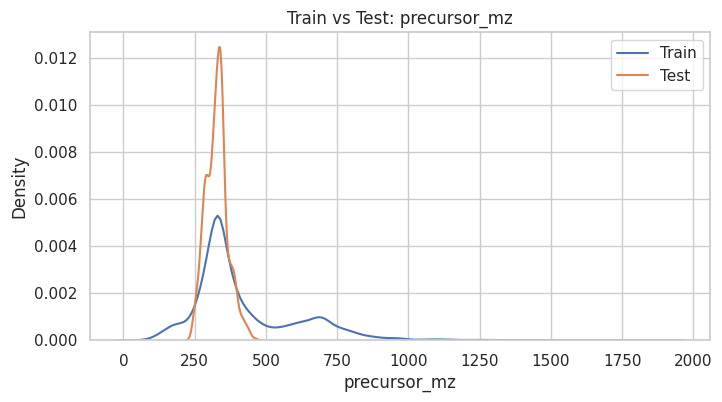

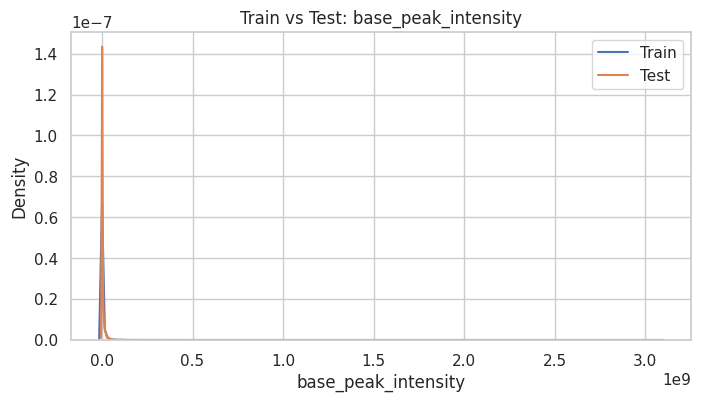

In [30]:
numeric_cols = [
    col for col in [
        "precursor_mz",
        "num_peaks",
        "base_peak_intensity"
    ]
    if col in train.columns and col in test.columns
]

for col in numeric_cols:
    fig, ax = plt.subplots(figsize=(8, 4))

    sns.kdeplot(
        train[col].dropna().sample(
            min(50000, train[col].notna().sum()),
            random_state=42
        ),
        label="Train",
        ax=ax
    )

    sns.kdeplot(
        test[col].dropna(),
        label="Test",
        ax=ax
    )

    ax.set_title(f"Train vs Test: {col}")
    ax.legend()

    plt.show()

## 6-2: Comparison of adducts and ionization modes
If there is a discrepancy between the distribution of the entire training dataset and that of the test dataset, consider prioritizing data that aligns more closely with the measurement conditions of the test set, rather than treating all training data equally.

In [31]:
for col in ["adduct", "ionization_mode"]:
    comparison = pd.concat(
        [
            train[col].value_counts(normalize=True).rename("Train"),
            test[col].value_counts(normalize=True).rename("Test")
        ],
        axis=1
    ).fillna(0)

    display(comparison.sort_values("Test", ascending=False))

,Train,Test
adduct,,
[M+H]+,5.215707e-01,0.790602
[M-H]-,1.833700e-01,0.159110
[M+CH2O2-H]-,3.275624e-02,0.025556
[M+Na]+,7.012578e-02,0.018137
[M+NH4]+,2.104734e-02,0.003298
...,...,...
[M-H2O2]2+,3.937616e-07,0.000000
[2M-H5O3]+,3.937616e-07,0.000000
[M+C2H7OS]+,3.937616e-07,0.000000


,Train,Test
ionization_mode,,
positive,0.748005,0.813685
negative,0.251995,0.186315


## 6-3: Aggregation at the molecular level
Analyses can be performed based on the premise that multiple spectra may exist for a single molecule, by utilizing `molecule_id`.

In [32]:
test_molecule_summary = (
    test.groupby("molecule_id")
    .agg(
        n_spectra=("spectrum_id", "count"),
        n_adducts=("adduct", "nunique"),
        n_ionization_modes=("ionization_mode", "nunique"),
        precursor_mz_min=("precursor_mz", "min"),
        precursor_mz_max=("precursor_mz", "max"),
        precursor_mz_median=("precursor_mz", "median")
    )
)

display(test_molecule_summary.head(10))

,n_spectra,n_adducts,n_ionization_modes,precursor_mz_min,precursor_mz_max,precursor_mz_median
molecule_id,,,,,,
m_005e53,4,2,2,373.0562,375.0709,375.07090
m_006153,6,2,2,340.1416,342.1569,341.14920
m_00b5aa,2,1,1,307.2023,307.2023,307.20230
m_01e922,3,1,1,250.1444,250.1444,250.14440
m_0259d4,7,2,2,340.1775,384.1681,340.17750
m_02d188,2,1,1,346.1319,346.1319,346.13190
m_0318b5,3,1,1,379.1936,379.1936,379.19360
m_043e86,3,1,1,290.1073,290.1073,290.10730
m_050bf1,2,1,1,326.1717,326.1718,326.17175


# Step 7: Designing the validation Dataset
Since the training data lacks `molecule_id`, cross-validation is performed by grouping entries based on their `inchikey14`.  
Ensuring `ovarlap=0` across all folds confirms that the same molecular structures are not present in both the training and validation sets.  
Note, however, that this splitting strategy is intended to evaluate performance on unseen structures. In an actual competition, searching against a library of known molecules can also be effective, so the approach should be chosen based on the specific requirements of the task.

In [35]:
groups = train["inchikey14"]

gkf = GroupKFold(n_splits=5)

fold_info = []

for fold, (tr_idx, val_idx) in enumerate(
    gkf.split(train, groups=groups)
):
    tr_keys = set(
        train.iloc[tr_idx]["inchikey14"]
    )
    val_keys = set(
        train.iloc[val_idx]["inchikey14"]
    )

    overlap = tr_keys & val_keys

    fold_info.append({
        "fold": fold,
        "trian_spectra": len(tr_idx),
        "valid_spectra": len(val_idx),
        "train_molecules": len(tr_keys),
        "valid_molecules": len(val_keys),
        "overlap": len(overlap)
    })

display(pd.DataFrame(fold_info))

,fold,trian_spectra,valid_spectra,train_molecules,valid_molecules,overlap
0,0,2031686,507922,220648,55162,0
1,1,2031686,507922,220648,55162,0
2,2,2031686,507922,220648,55162,0
3,3,2031687,507921,220648,55162,0
4,4,2031687,507921,220648,55162,0
